In [5]:
import pandas as pd
import numpy as np
import os
import glob
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

data_path = os.getcwd()

In [6]:
csv_files = glob.glob(os.path.join(data_path, "*.csv"))

dataframes = {}

print("Số lượng file CSV:", len(csv_files))

for file in csv_files:
    name = os.path.basename(file)
    df = pd.read_csv(file)

    dataframes[name] = df

    print("\nFILE:", name)
    print("Shape:", df.shape)
    display(df.head())

Số lượng file CSV: 2

FILE: GLDS-563_proteomics_EVPs_sample_metadata.csv
Shape: (29, 7)


,Area,Astronaut,Sample,PreVpost_flight,PreVpost,Timepoint,ImmediateVLongTerm
0,A5,C001,C001_1,pre-flight 1,Pre-flight,June_Pre,Preflight
1,B5,C001,C001_2,pre-flight 2,Pre-flight,Aug_Pre,Preflight
2,C5,C001,C001_3,pre-flight 3,Pre-flight,Sept_Pre,Preflight
3,D5,C001,C001_4,post-flight 1,Post-flight,Sept_Post,Immediate Postflight
4,E5,C001,C001_5,post-flight 2,Post-flight,Nov_Post,Longterm Postflight



FILE: GLDS-563_proteomics_plasma_metadata_all_samples_collapsed.csv
Shape: (21, 5)


,Sample_name,Astronaut,PreVpost,Timepoint,ImmediateVLongTerm
0,C001_June_Pre,C001,Preflight,June_Pre,Preflight
1,C001_Aug_Pre,C001,Preflight,Aug_Pre,Preflight
2,C001_Sept_Pre,C001,Preflight,Sept_Pre,Preflight
3,C001_Sept_Post,C001,Postflight,Sept_Post,Immediate_Postflight
4,C001_Dec_Post,C001,Postflight,Dec_Post,Longterm_Postflight


In [7]:
for name, df in dataframes.items():
    print("\nFILE:", name)

    print("\nSố mẫu theo Astronaut:")
    display(df["Astronaut"].value_counts())

    print("\nSố mẫu theo Timepoint:")
    display(df["Timepoint"].value_counts())

    print("\nPhân loại Pre/Post:")
    display(df["PreVpost"].value_counts())


FILE: GLDS-563_proteomics_EVPs_sample_metadata.csv

Số mẫu theo Astronaut:


Astronaut
C001     6
C002     6
C003     6
C004     6
Ctrl2    1
000-1    1
000-2    1
000-3    1
000-4    1
Name: count, dtype: int64


Số mẫu theo Timepoint:


Timepoint
Control      5
Aug_Pre      4
June_Pre     4
Sept_Pre     4
Sept_Post    4
Nov_Post     4
Dec_Post     4
Name: count, dtype: int64


Phân loại Pre/Post:


PreVpost
Pre-flight     12
Post-flight    12
no flight       5
Name: count, dtype: int64

... (2 outputs left out)


Số mẫu theo Timepoint:


Timepoint
June_Pre     4
Aug_Pre      4
Sept_Post    4
Dec_Post     4
Sept_Pre     3
Nov_Post     2
Name: count, dtype: int64


Phân loại Pre/Post:


PreVpost
Preflight     11
Postflight    10
Name: count, dtype: int64

In [8]:
proteomics_file = os.path.join(
    data_path,
    "GLDS-563_proteomics_plasma_proteomics_preprocessed_data.tsv"
)

proteomics_df = pd.read_csv(
    proteomics_file,
    sep="\t",
    low_memory=False
)

print("Shape:", proteomics_df.shape)
print("\nColumns:")
print(proteomics_df.columns.tolist())

display(proteomics_df.head())

Shape: (81817, 9)

Columns:
['Sample Name', 'Plate ID', 'Protein Group', 'Intensity (Log10)', 'Protein Names', 'Gene Names', 'Biological Process', 'Molecular Function', 'Cellular Component']


,Sample Name,Plate ID,Protein Group,Intensity (Log10),Protein Names,Gene Names,Biological Process,Molecular Function,Cellular Component
0,C004_Sept_Pre-2,2022ms0189,Q9UBU3-2,3.4807,"Isoform of Q9UBU3, Isoform 2 of Appetite-regul...",GHRL,NaN,NaN,NaN
1,C001_Aug_Pre-1,2022ms0187,Q9UBU3-2,3.6400,"Isoform of Q9UBU3, Isoform 2 of Appetite-regul...",GHRL,NaN,NaN,NaN
2,C001_Aug_Pre-2,2022ms0189,Q9UBU3-2,3.4630,"Isoform of Q9UBU3, Isoform 2 of Appetite-regul...",GHRL,NaN,NaN,NaN
3,C001_Dec_Post-1,2022ms0188,Q9UBU3-2,3.4125,"Isoform of Q9UBU3, Isoform 2 of Appetite-regul...",GHRL,NaN,NaN,NaN
4,C001_Dec_Post-2,2022ms0189,Q9UBU3-2,3.2762,"Isoform of Q9UBU3, Isoform 2 of Appetite-regul...",GHRL,NaN,NaN,NaN


In [ ]:
#Kiểm tra chất lượng dữ liệu
print("Số dòng:", proteomics_df.shape[0])
print("Số cột:", proteomics_df.shape[1])

print("\nGiá trị thiếu từng cột:")
display(proteomics_df.isnull().sum())

print("\nTỷ lệ thiếu (%):")
display(
    (proteomics_df.isnull().mean() * 100).round(2)
)

print("\nSố dòng trùng hoàn toàn:", proteomics_df.duplicated().sum())

print("\nKiểu dữ liệu:")
print(proteomics_df.dtypes)

Số dòng: 81817
Số cột: 9

Giá trị thiếu từng cột:


Sample Name               0
Plate ID                  0
Protein Group             0
Intensity (Log10)         0
Protein Names          1547
Gene Names             1547
Biological Process    25997
Molecular Function    26474
Cellular Component    25071
dtype: int64


Tỷ lệ thiếu (%):


Sample Name            0.00
Plate ID               0.00
Protein Group          0.00
Intensity (Log10)      0.00
Protein Names          1.89
Gene Names             1.89
Biological Process    31.77
Molecular Function    32.36
Cellular Component    30.64
dtype: float64


Số dòng trùng hoàn toàn: 0

Kiểu dữ liệu:
Sample Name            object
Plate ID               object
Protein Group          object
Intensity (Log10)     float64
Protein Names          object
Gene Names             object
Biological Process     object
Molecular Function     object
Cellular Component     object
dtype: object


In [ ]:
#Thống kê số mẫu và protein
print("Số mẫu duy nhất:",
      proteomics_df["Sample Name"].nunique())

print("Số Protein Group duy nhất:",
      proteomics_df["Protein Group"].nunique())

print("\nSố lượng mẫu:")
display(
    proteomics_df["Sample Name"].value_counts().head(20)
)

print("\nSố lượng protein:")
display(
    proteomics_df["Protein Group"].value_counts().head(20)
)

Số mẫu duy nhất: 42
Số Protein Group duy nhất: 2992

Số lượng mẫu:


Sample Name
C003_Dec_Post-1     2779
C003_Dec_Post-2     2694
C004_Nov_Post-1     2671
C004_Nov_Post-2     2578
C004_Dec_Post-1     2411
C001_Dec_Post-1     2388
C001_Dec_Post-2     2319
C004_Dec_Post-2     2318
C004_Sept_Post-1    2254
C004_Sept_Post-2    2161
C004_June_Pre-1     2048
C004_June_Pre-2     1952
C002_Aug_Pre-1      1940
C004_Aug_Pre-1      1932
C003_June_Pre-1     1919
C001_Sept_Post-1    1908
C004_Aug_Pre-2      1904
C001_Aug_Pre-1      1892
C001_Sept_Post-2    1883
C002_June_Pre-1     1857
Name: count, dtype: int64


Số lượng protein:


Protein Group
A0A0B4J1Y8    42
A0A0B4J1V6    42
A0A0B4J1V2    42
A0A0B4J1V0    42
A0A0B4J1U7    42
A0A0A0MS15    42
A0A096LPE2    42
A0A087X1V8    42
A0A087X0D5    42
A0A087WUZ3    42
A0A087WSY6    42
A0A087WSX0    42
A0A075B6Q5    42
A0A075B6K5    42
A0A075B6K4    42
A0A075B6J9    42
P61225        42
Q9NP55-2      42
Q9HD89        42
Q9HCU4        42
Name: count, dtype: int64

In [ ]:
#Kiểm tra trùng lặp mẫu và protein
duplicate_pairs = proteomics_df.duplicated(
    subset=["Sample Name", "Protein Group"]
)

print("Số cặp Sample-Protein bị trùng:", duplicate_pairs.sum())

display(
    proteomics_df[
        duplicate_pairs
    ].head(10)
)

Số cặp Sample-Protein bị trùng: 0


,Sample Name,Plate ID,Protein Group,Intensity (Log10),Protein Names,Gene Names,Biological Process,Molecular Function,Cellular Component


count    81817.000000
mean         4.159770
std          0.952219
min          0.699000
25%          3.476300
50%          3.975600
75%          4.700000
max          7.597400
Name: Intensity (Log10), dtype: float64


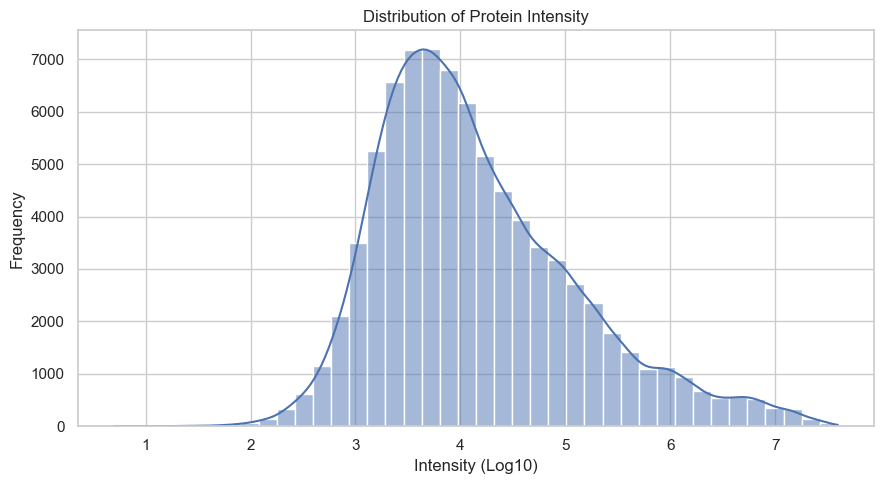

In [ ]:
#Thống kê Intensity
intensity = proteomics_df["Intensity (Log10)"]

print(intensity.describe())

plt.figure(figsize=(9, 5))
sns.histplot(intensity.dropna(), bins=40, kde=True)

plt.title("Distribution of Protein Intensity")
plt.xlabel("Intensity (Log10)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

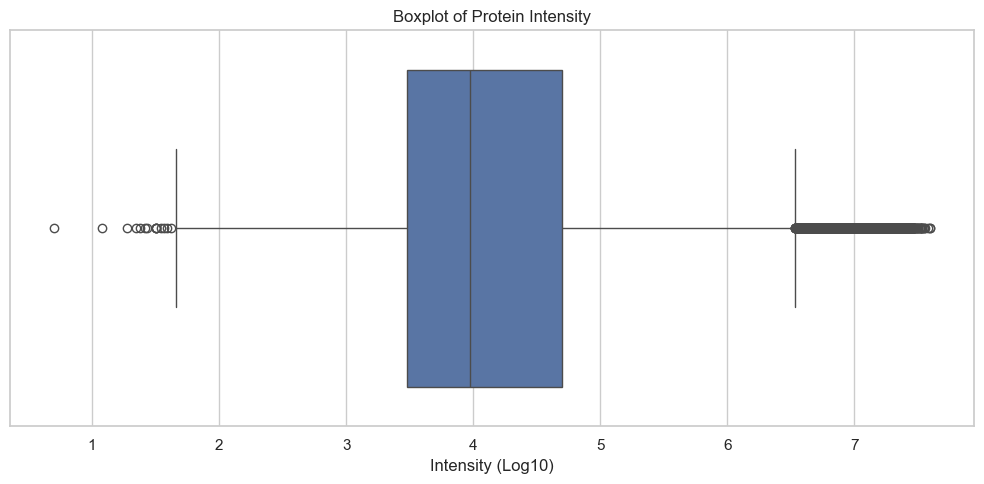

In [ ]:
#Boxplot Intensity
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=proteomics_df["Intensity (Log10)"]
)

plt.title("Boxplot of Protein Intensity")
plt.xlabel("Intensity (Log10)")

plt.tight_layout()
plt.show()

Sample Name
C003_Dec_Post-1     2779
C003_Dec_Post-2     2694
C004_Nov_Post-1     2671
C004_Nov_Post-2     2578
C004_Dec_Post-1     2411
C001_Dec_Post-1     2388
C001_Dec_Post-2     2319
C004_Dec_Post-2     2318
C004_Sept_Post-1    2254
C004_Sept_Post-2    2161
C004_June_Pre-1     2048
C004_June_Pre-2     1952
C002_Aug_Pre-1      1940
C004_Aug_Pre-1      1932
C003_June_Pre-1     1919
C001_Sept_Post-1    1908
C004_Aug_Pre-2      1904
C001_Aug_Pre-1      1892
C001_Sept_Post-2    1883
C002_June_Pre-1     1857
C002_Aug_Pre-2      1841
C002_June_Pre-2     1829
C003_June_Pre-2     1826
C003_Sept_Post-1    1808
C002_Nov_Post-2     1798
C003_Sept_Post-2    1785
C002_Nov_Post-1     1783
C002_Sept_Post-1    1781
C002_Sept_Post-2    1780
C002_Dec_Post-1     1766
C001_Aug_Pre-2      1762
C001_June_Pre-2     1741
C002_Dec_Post-2     1731
C001_June_Pre-1     1724
C003_Aug_Pre-2      1696
C001_Sept_Pre-2     1679
C004_Sept_Pre-2     1667
C001_Sept_Pre-1     1660
C004_Sept_Pre-1     1648
C003_Aug_Pre-

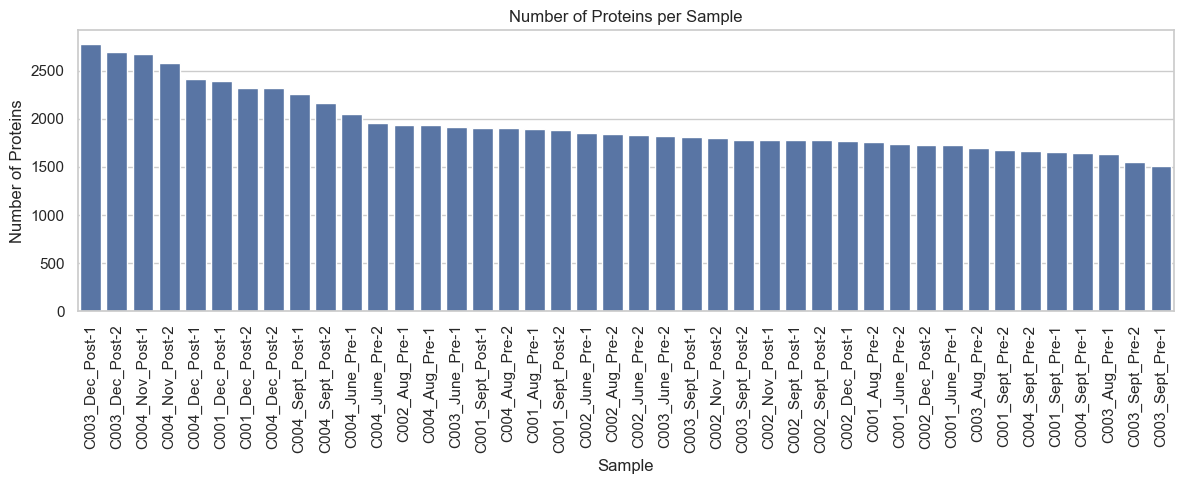

In [ ]:
#Kiểm tra số protein trên mỗi mẫu
protein_per_sample = (
    proteomics_df.groupby("Sample Name")["Protein Group"]
    .nunique()
    .sort_values(ascending=False)
)

display(protein_per_sample)

plt.figure(figsize=(12, 5))

sns.barplot(
    x=protein_per_sample.index,
    y=protein_per_sample.values
)

plt.title("Number of Proteins per Sample")
plt.xlabel("Sample")
plt.ylabel("Number of Proteins")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [ ]:
#Kiểm tra mã mẫu để chuẩn bị ghép metadata
# Tạo mã mẫu gốc để kiểm tra, chưa dùng để gộp dữ liệu
proteomics_df["Base_Sample"] = (
    proteomics_df["Sample Name"]
    .str.replace(r"-\d+$", "", regex=True)
)

print("Số Sample Name:", proteomics_df["Sample Name"].nunique())
print("Số Base Sample:", proteomics_df["Base_Sample"].nunique())

print("\nCác mẫu sau khi bỏ hậu tố:")
display(
    proteomics_df[
        ["Sample Name", "Base_Sample"]
    ].drop_duplicates().head(20)
)
#Kiểm tra mã mẫu có khớp metadata không
plasma_metadata = dataframes[
    "GLDS-563_proteomics_plasma_metadata_all_samples_collapsed.csv"
]

tsv_samples = set(proteomics_df["Base_Sample"].dropna())
metadata_samples = set(plasma_metadata["Sample_name"].dropna())

print("Mẫu có trong cả hai:", len(tsv_samples & metadata_samples))

print("\nMẫu chỉ có trong TSV:")
print(sorted(tsv_samples - metadata_samples))

print("\nMẫu chỉ có trong metadata:")
print(sorted(metadata_samples - tsv_samples))

Số Sample Name: 42
Số Base Sample: 21

Các mẫu sau khi bỏ hậu tố:


,Sample Name,Base_Sample
0,C004_Sept_Pre-2,C004_Sept_Pre
1,C001_Aug_Pre-1,C001_Aug_Pre
2,C001_Aug_Pre-2,C001_Aug_Pre
3,C001_Dec_Post-1,C001_Dec_Post
4,C001_Dec_Post-2,C001_Dec_Post
5,C001_June_Pre-1,C001_June_Pre
6,C001_June_Pre-2,C001_June_Pre
7,C001_Sept_Post-1,C001_Sept_Post
8,C001_Sept_Post-2,C001_Sept_Post
9,C001_Sept_Pre-1,C001_Sept_Pre


Mẫu có trong cả hai: 21

Mẫu chỉ có trong TSV:
[]

Mẫu chỉ có trong metadata:
[]


Số mẫu: 42
Số protein trung bình: 1948.0238095238096
Số protein thấp nhất: 1512
Số protein cao nhất: 2779


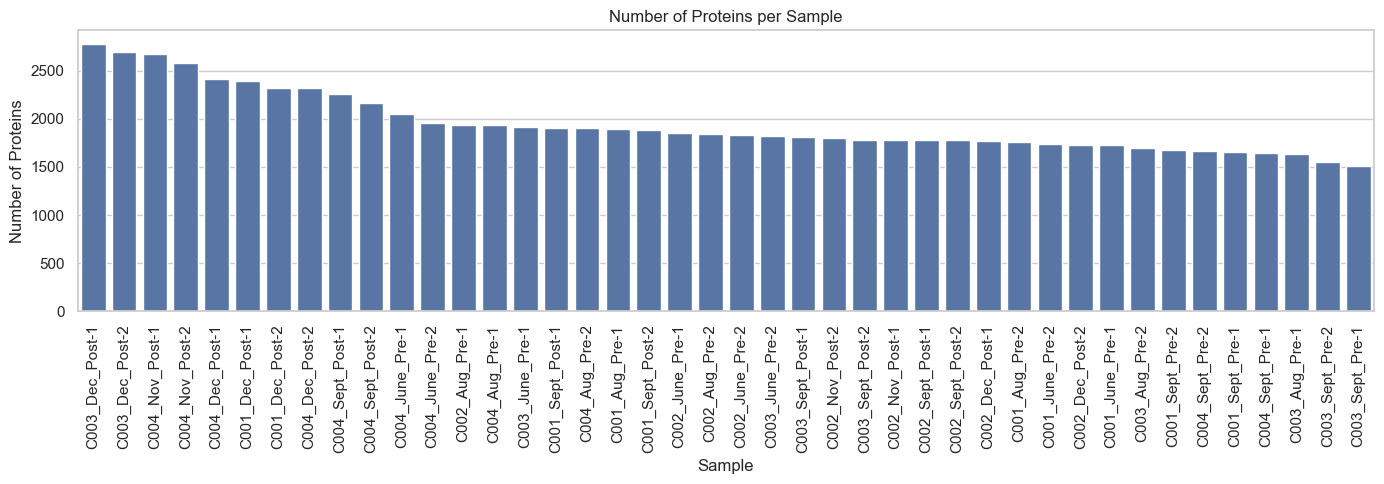

In [20]:
protein_per_sample = (
    proteomics_df.groupby("Sample Name")["Protein Group"]
    .nunique()
    .sort_values(ascending=False)
)

print("Số mẫu:", len(protein_per_sample))
print("Số protein trung bình:", protein_per_sample.mean())
print("Số protein thấp nhất:", protein_per_sample.min())
print("Số protein cao nhất:", protein_per_sample.max())

plt.figure(figsize=(14, 5))

sns.barplot(
    x=protein_per_sample.index,
    y=protein_per_sample.values
)

plt.title("Number of Proteins per Sample")
plt.xlabel("Sample")
plt.ylabel("Number of Proteins")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

Số protein: 2992

Phân bố số mẫu có protein:


Sample Name
1      12
2      57
3      84
4      88
5      82
6      89
7      64
8      68
9      74
10     69
11     48
12     47
13     44
14     43
15     45
16     42
17     33
18     24
19     32
20     39
21     32
22     28
23     33
24     34
25     34
26     26
27     38
28     36
29     35
30     24
31     42
32     41
33     43
34     26
35     45
36     42
37     53
38     65
39     61
40     98
41    115
42    957
Name: count, dtype: int64

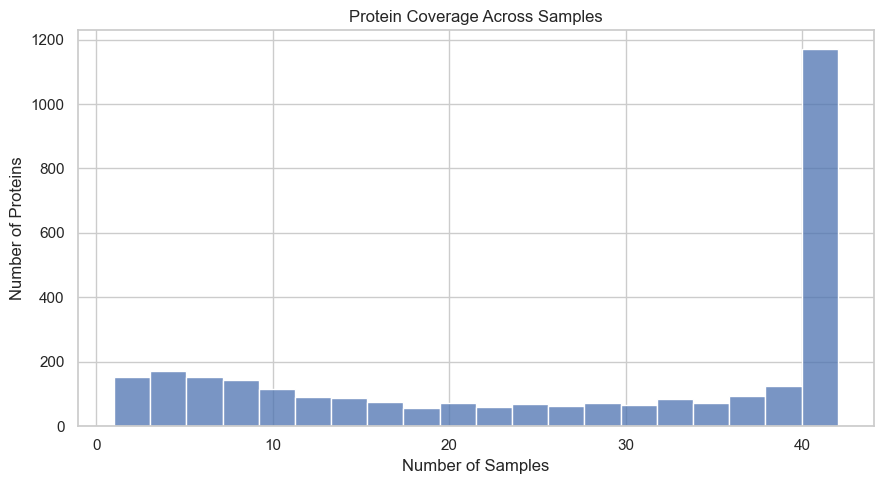

In [21]:
protein_coverage = (
    proteomics_df.groupby("Protein Group")["Sample Name"]
    .nunique()
    .sort_values(ascending=False)
)

print("Số protein:", len(protein_coverage))

print("\nPhân bố số mẫu có protein:")
display(protein_coverage.value_counts().sort_index())

plt.figure(figsize=(9, 5))

sns.histplot(
    protein_coverage,
    bins=20
)

plt.title("Protein Coverage Across Samples")
plt.xlabel("Number of Samples")
plt.ylabel("Number of Proteins")

plt.tight_layout()
plt.show()

In [22]:
missing_by_sample = (
    proteomics_df.groupby("Sample Name")["Intensity (Log10)"]
    .apply(lambda x: x.isnull().sum())
)

display(missing_by_sample)

print("Tổng số Intensity bị thiếu:", missing_by_sample.sum())

Sample Name
C001_Aug_Pre-1      0
C001_Aug_Pre-2      0
C001_Dec_Post-1     0
C001_Dec_Post-2     0
C001_June_Pre-1     0
C001_June_Pre-2     0
C001_Sept_Post-1    0
C001_Sept_Post-2    0
C001_Sept_Pre-1     0
C001_Sept_Pre-2     0
C002_Aug_Pre-1      0
C002_Aug_Pre-2      0
C002_Dec_Post-1     0
C002_Dec_Post-2     0
C002_June_Pre-1     0
C002_June_Pre-2     0
C002_Nov_Post-1     0
C002_Nov_Post-2     0
C002_Sept_Post-1    0
C002_Sept_Post-2    0
C003_Aug_Pre-1      0
C003_Aug_Pre-2      0
C003_Dec_Post-1     0
C003_Dec_Post-2     0
C003_June_Pre-1     0
C003_June_Pre-2     0
C003_Sept_Post-1    0
C003_Sept_Post-2    0
C003_Sept_Pre-1     0
C003_Sept_Pre-2     0
C004_Aug_Pre-1      0
C004_Aug_Pre-2      0
C004_Dec_Post-1     0
C004_Dec_Post-2     0
C004_June_Pre-1     0
C004_June_Pre-2     0
C004_Nov_Post-1     0
C004_Nov_Post-2     0
C004_Sept_Post-1    0
C004_Sept_Post-2    0
C004_Sept_Pre-1     0
C004_Sept_Pre-2     0
Name: Intensity (Log10), dtype: int64

Tổng số Intensity bị thiếu: 0


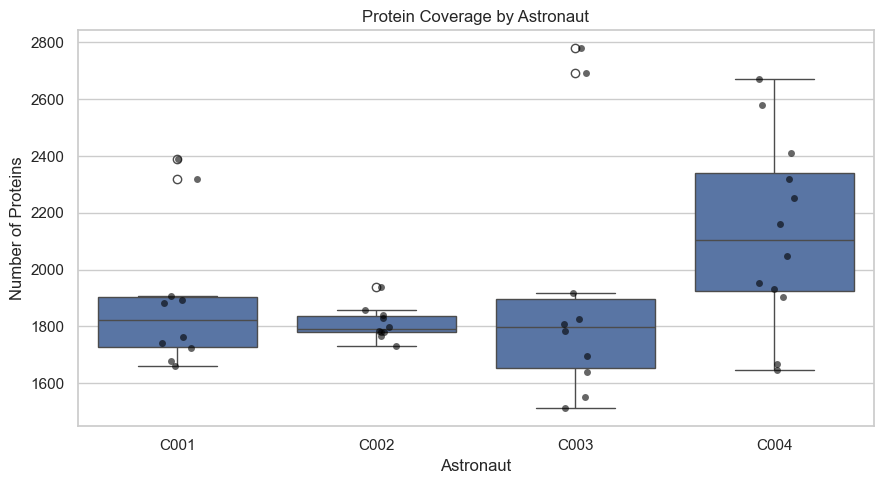

In [23]:
# Tách mã phi hành gia
proteomics_df["Astronaut"] = (
    proteomics_df["Sample Name"].str.extract(r"^(C\d+)")
)

# Đếm protein trên từng mẫu
sample_counts = (
    proteomics_df.groupby(["Astronaut", "Sample Name"])
    ["Protein Group"].nunique()
    .reset_index(name="Protein_Count")
)

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=sample_counts,
    x="Astronaut",
    y="Protein_Count"
)

sns.stripplot(
    data=sample_counts,
    x="Astronaut",
    y="Protein_Count",
    color="black",
    alpha=0.6
)

plt.title("Protein Coverage by Astronaut")
plt.xlabel("Astronaut")
plt.ylabel("Number of Proteins")

plt.tight_layout()
plt.show()

Biểu đồ Protein Coverage by Astronaut cho thấy số lượng protein được phát hiện có sự khác biệt giữa các phi hành gia. C004 có trung vị và mức độ phân tán cao nhất, trong khi C002 có dữ liệu tập trung và ổn định hơn. C003 xuất hiện một số mẫu có số lượng protein chênh lệch đáng kể. Kết quả cho thấy độ bao phủ protein không đồng đều giữa các mẫu, cần được xem xét trong quá trình tiền xử lý và phân tích dữ liệu tiếp theo.

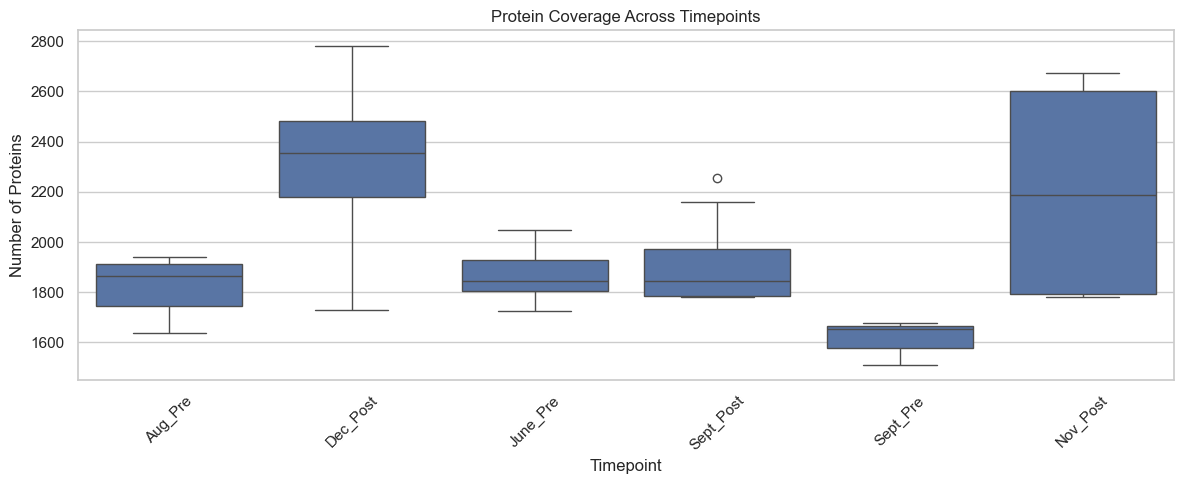

In [24]:
sample_counts = (
    proteomics_df.groupby("Sample Name")["Protein Group"]
    .nunique()
    .reset_index(name="Protein_Count")
)

sample_counts["Astronaut"] = (
    sample_counts["Sample Name"].str.extract(r"^(C\d+)")
)

sample_counts["Timepoint"] = (
    sample_counts["Sample Name"]
    .str.extract(r"^[^_]+_([^ -]+_[^ -]+)")
)

plt.figure(figsize=(12, 5))

sns.boxplot(
    data=sample_counts,
    x="Timepoint",
    y="Protein_Count"
)

plt.title("Protein Coverage Across Timepoints")
plt.xlabel("Timepoint")
plt.ylabel("Number of Proteins")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Biểu đồ Protein Coverage Across Timepoints cho thấy số lượng protein được phát hiện có sự thay đổi giữa các thời điểm khảo sát. Trong các mốc trước chuyến bay, Sept_Pre có số lượng protein thấp nhất, trong khi Aug_Pre và June_Pre có mức phân bố tương đối ổn định. Ở các mốc sau chuyến bay, Dec_Post có trung vị cao nhất, còn Nov_Post có độ phân tán lớn. Kết quả cho thấy độ bao phủ protein khác nhau giữa các thời điểm, cần được xem xét khi phân tích sự thay đổi protein theo thời gian.

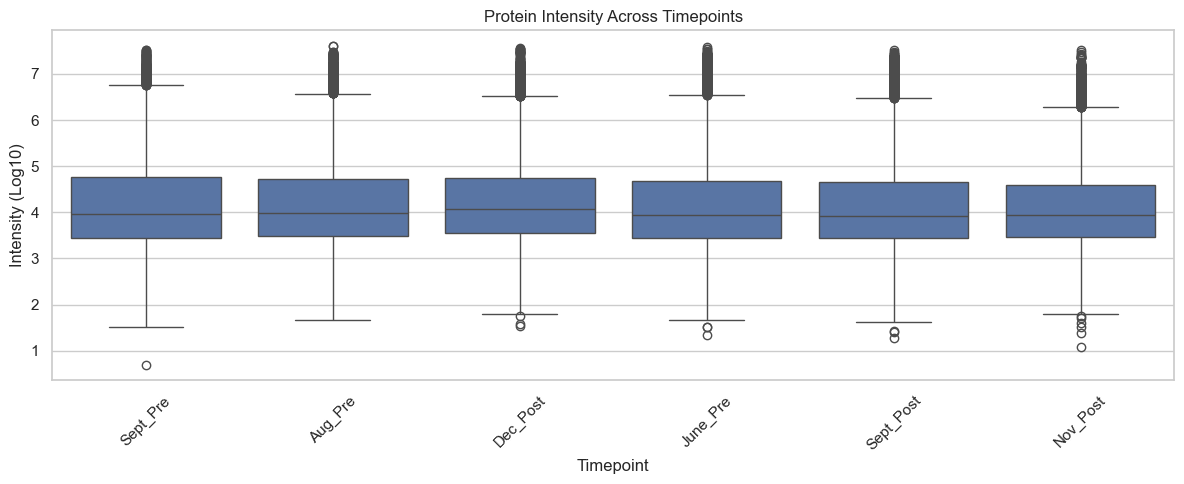

In [28]:
proteomics_df["Timepoint"] = (
    proteomics_df["Sample Name"]
    .str.extract(r"^[^_]+_([^ -]+_[^ -]+)")
)

plt.figure(figsize=(12, 5))

sns.boxplot(
    data=proteomics_df,
    x="Timepoint",
    y="Intensity (Log10)"
)

plt.title("Protein Intensity Across Timepoints")
plt.xlabel("Timepoint")
plt.ylabel("Intensity (Log10)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Biểu đồ Protein Intensity Across Timepoints thể hiện phân bố cường độ protein tại các thời điểm trước và sau chuyến bay. Kết quả cho thấy trung vị cường độ protein giữa các thời điểm tương đối ổn định, dao động khoảng 3,9–4,1 trên thang Log10. Các nhóm đều xuất hiện một số giá trị ngoại lệ ở cả phía cao và thấp. Nhìn chung, phân bố cường độ protein không có sự khác biệt rõ rệt khi quan sát ở mức tổng thể. Tuy nhiên, cần phân tích từng protein cụ thể để xác định những thay đổi sinh học theo thời gian.